# AI in Cyber Security — Unit 1 Mini Project

**Dataset:** Aposemat IoT-23, capture `CTU-IoT-Malware-Capture-1-1` (Stratosphere Laboratory, CC BY 4.0)

Tasks 1–4. Each task calls the same module the standalone scripts in `src/` use, so the
notebook and the scripts cannot drift apart and produce different numbers.

Run order matters: Task 4 reads the results table Task 3 writes.


## Task 1 — Environment check

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))

import verify_setup
verify_setup.main()

Environment check - AI in Cyber Security, Unit 1 mini project
Python      : 3.14.5
Platform    : Windows 11
Interpreter : C:\Users\Rudraraj Radhwani\projects\ai-cybersecurity-unit1-mini-project-rudraraj\.venv\Scripts\python.exe

Required packages:
  OK    numpy          2.5.3


  OK    pandas         3.0.6


  OK    scikit-learn   1.9.1


  OK    matplotlib     3.11.2


  OK    seaborn        0.13.2
  OK    jupyter        (no __version__)

Dataset:


  OK    iot23_sample.csv.gz
        84,063 rows x 21 columns
        capture window 2018-05-09 15:30:31.015073061 -> 2018-05-14 07:24:41.031404972
        malicious 53.47%

Setup is valid. Next:
  python src/task2_eda.py
  python src/task3_ml.py
  python src/task4_dl.py


0

## Task 2 — Threat landscape analysis

Loads the dataset, characterises the threat indicators, and measures the
destination-port rule that the dataset's labels were derived from.

In [2]:
import task2_eda
task2_eda.main()


1. DATASET OVERVIEW


  rows            : 84,063
  columns         : 21
  capture window  : 2018-05-09 15:30:31.015073061  ->  2018-05-14 07:24:41.031404972
  duration        : 4 days
  source hosts    : 1,328
  destination IPs : 78,596
  destination ports: 28,361

  Class balance:
    Malicious      44,946  (53.47%)
    Benign         39,117  (46.53%)

  Attack types (detailed-label):
    PartOfAHorizontalPortScan      44,945  (53.466%)
    Benign                         39,117  (46.533%)
    C&C                                 1  ( 0.001%)

  Missing values per column:
    duration             66,354  (78.93%)
    orig_bytes           66,354  (78.93%)
    resp_bytes           66,354  (78.93%)

  INSIGHT: duration/orig_bytes/resp_bytes are missing together on the
  same rows. In Zeek these are absent when the connection was never
  answered -- a missing value here means 'no reply', not 'unknown'.
  That is why the project keeps explicit no_response / never_established
  flags rather than silently filling z

label       Benign  Malicious
conn_state                   
OTH           1471          0
REJ             43        354
RSTO             0          6
RSTOS0          20          0
RSTR             1        132
RSTRH            0          7
S0           37047      43804
S1               0          3
S2               0          3
SF             535        635
SH               0          2

  INSIGHT: 96.2% of ALL flows are conn_state S0 -- a
  connection attempt that got no reply at all. That is the signature of
  horizontal scanning: spray SYNs across many hosts, most never answer.

  Protocol by class:
label  Benign  Malicious  malicious_%
proto                                
icmp     1471          0         0.00
tcp      3710      44945        92.37
udp     33936          1         0.00

  Top 10 destination ports:
           flows  malicious  malicious_pct
id.resp_p                                 
23         22810      22810          100.0
8080       11232      11232          100.0

  wrote outputs\figures\fig1_threat_overview.png


  wrote outputs\figures\fig2_feature_distributions.png


  wrote outputs\figures\fig3_scanning_fanout.png

5. TABLES SAVED FOR THE REPORT
  wrote outputs\tables\task2_conn_state_by_class.csv
  wrote outputs\tables\task2_protocol_by_class.csv
  wrote outputs\tables\task2_top_destination_ports.csv
  wrote outputs\tables\task2_port_lookup_baseline.csv

Task 2 complete. Figures in outputs/figures, tables in outputs/tables.


### Figures produced

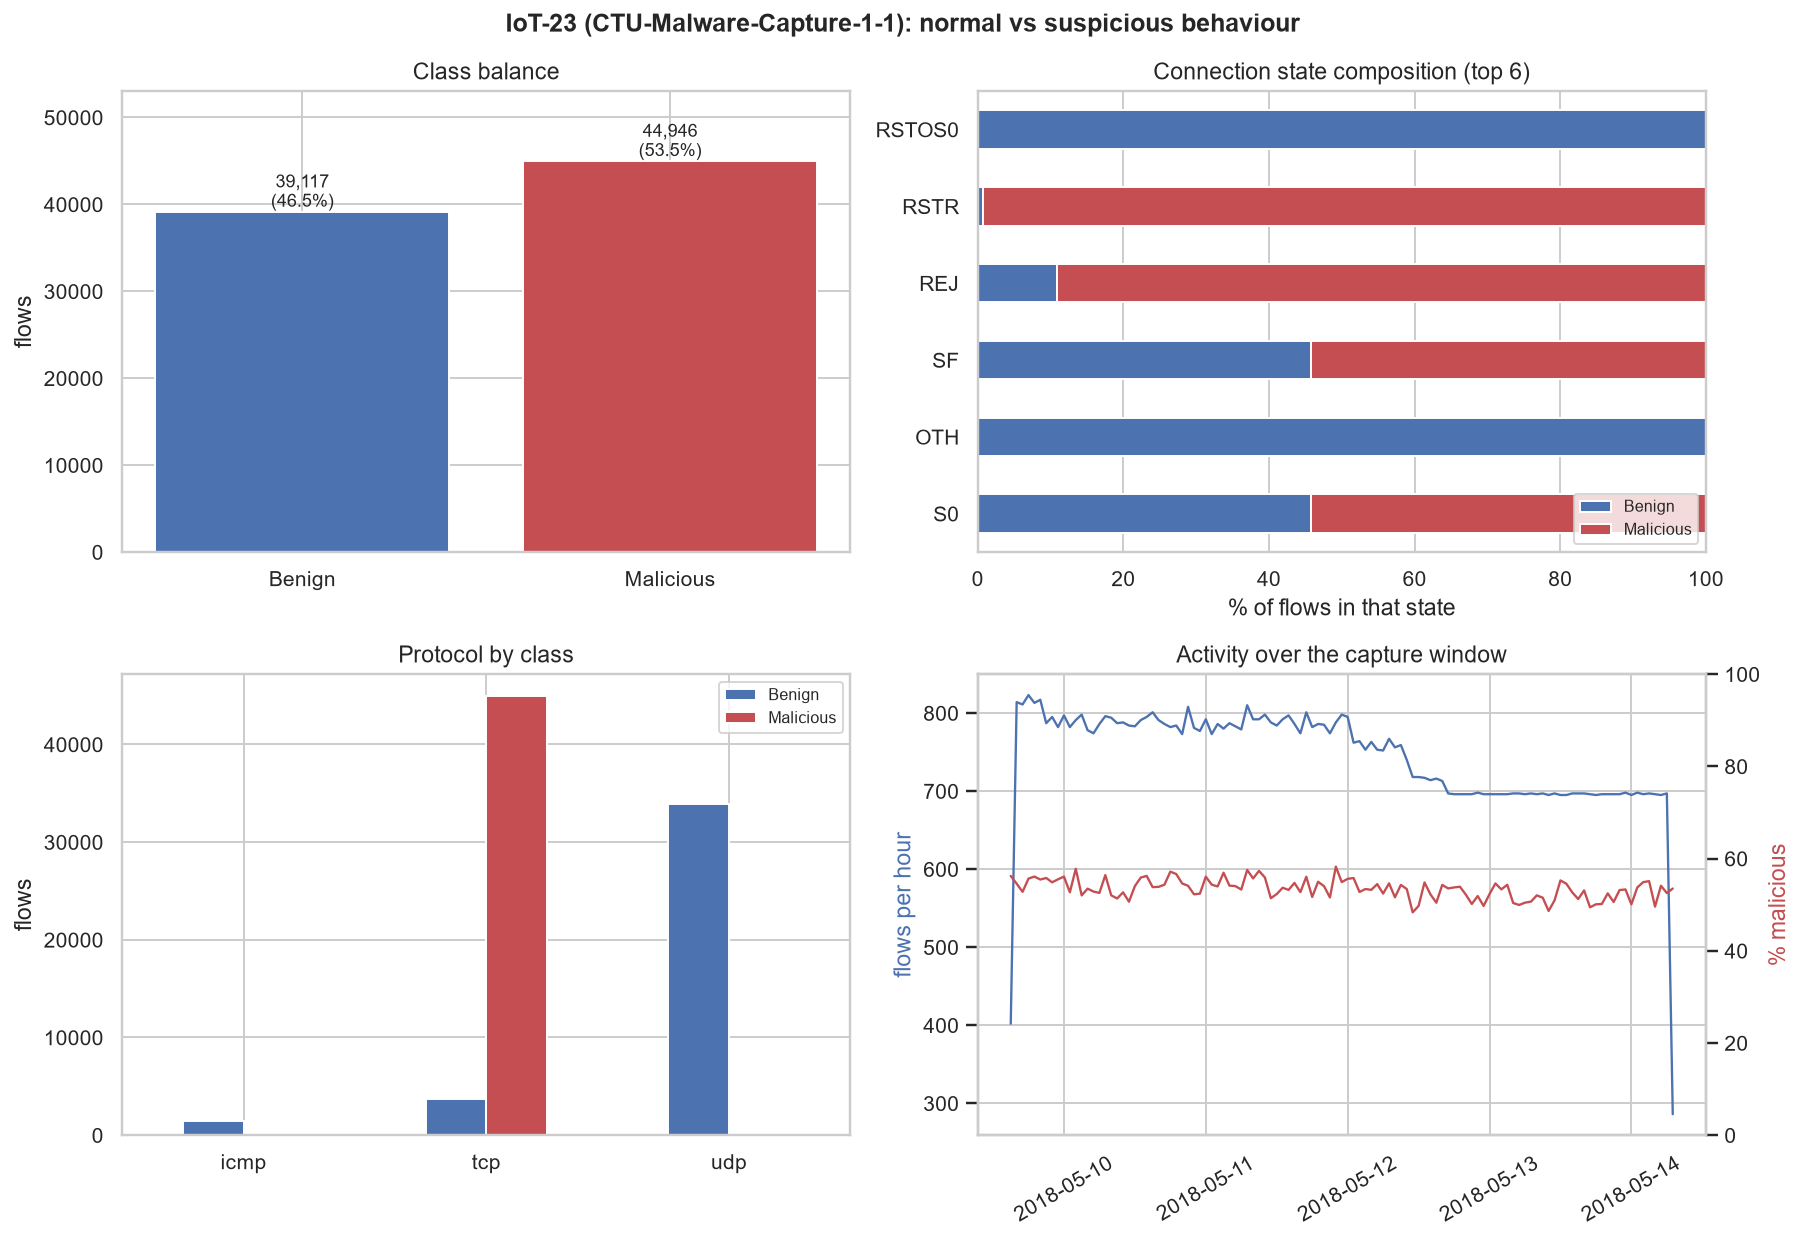

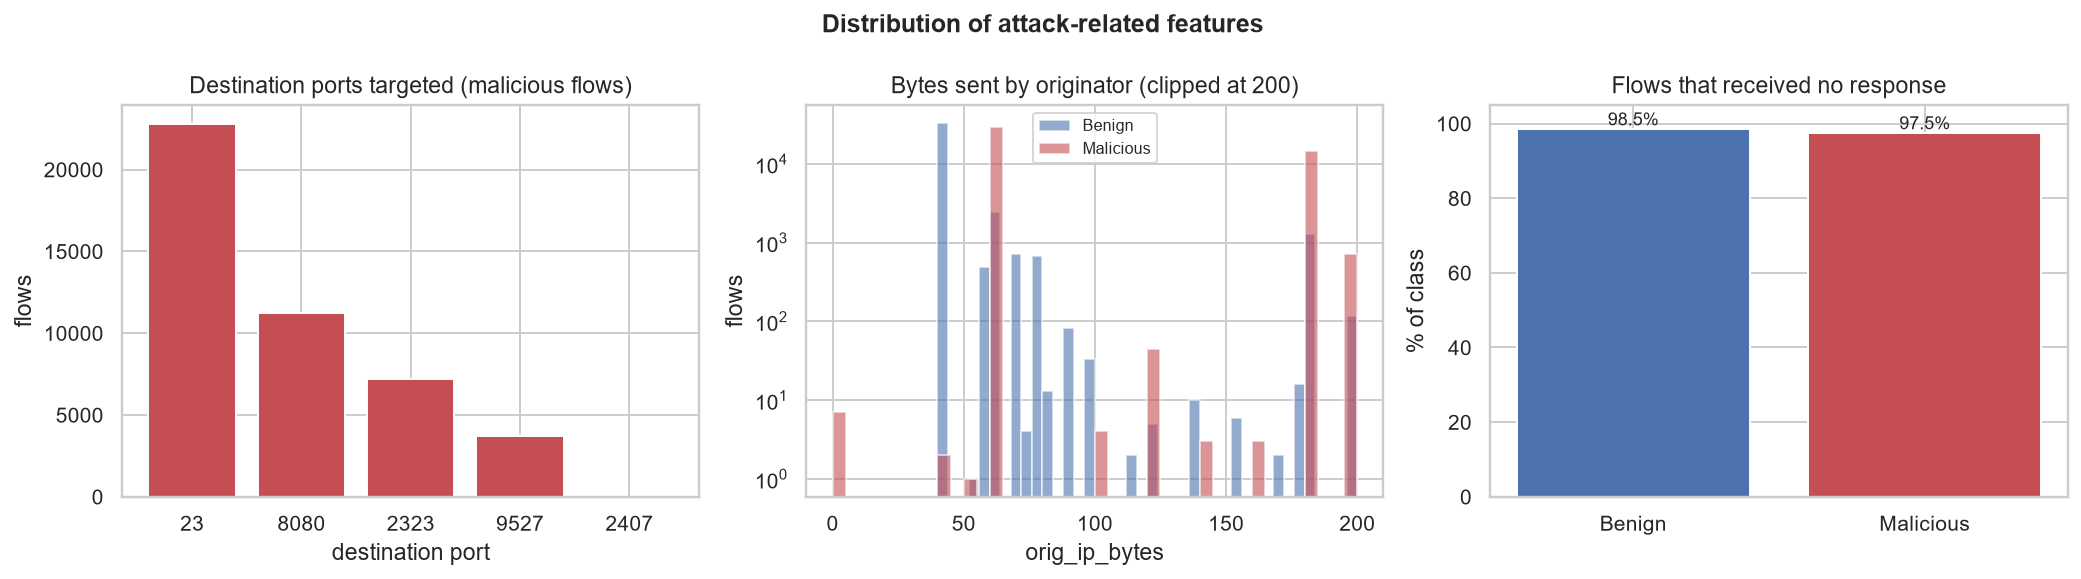

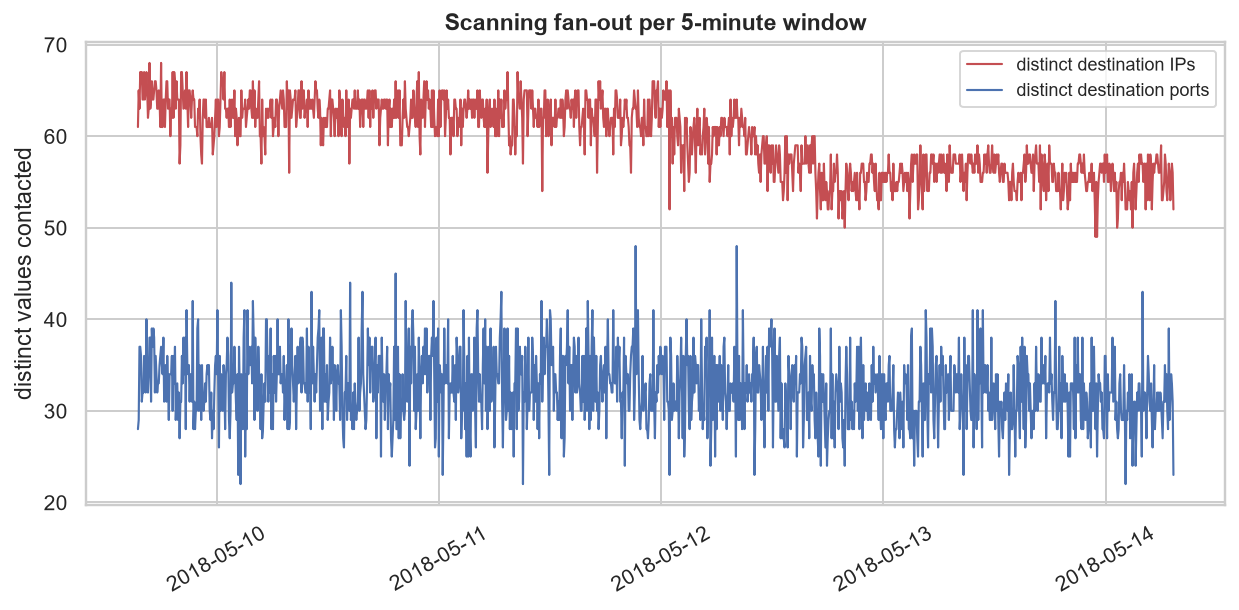

In [3]:
from IPython.display import Image, display
for name in ["fig1_threat_overview.png",
             "fig2_feature_distributions.png",
             "fig3_scanning_fanout.png"]:
    display(Image(filename=f"../outputs/figures/{name}"))

## Task 3 — Machine-learning threat classification

Preprocessing (missing values, encoding, normalisation), then Logistic Regression
and a Decision Tree, each trained with and without the leaking port columns.

The collapse check at the end is the part worth reading: it tests whether a model
is merely reproducing a one-feature rule.

In [4]:
import task3_ml
task3_ml.main()


1. LOAD AND SPLIT


  total rows : 84,063
  train      : 58,844  (2018-05-09 15:30:31.015073061 -> 2018-05-12 19:11:21.003218889)
  test       : 25,219  (2018-05-12 19:11:25.012140036 -> 2018-05-14 07:24:41.031404972)
  malicious rate  train 54.08%  test 52.03%

  TEMPORAL split, not random: the model is trained on the earlier
  period and tested on the later one, which is what a deployed
  detector actually faces.

2. PREPROCESSING
  numeric      : median imputation (+ was-missing indicator) -> StandardScaler
  boolean      : passed through unchanged
  categorical  : one-hot, rare levels (<30 rows) collapsed together

  The was-missing indicator matters here. A missing duration means the
  connection was never answered; filling it with the median alone would
  make that look like an ordinary short connection.

3. TRAINING

  [with_leak] 15 input columns


C:\Users\Rudraraj Radhwani\projects\ai-cybersecurity-unit1-mini-project-rudraraj\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)



  --- LogisticRegression (with_leak) ---
  class         precision    recall        F1   support
  benign           1.0000    0.9793    0.9896    12,098
  malicious        0.9813    1.0000    0.9906    13,121
  PR-AUC (malicious) : 0.9945
  confusion          : TP 13,121  FP 250  FN 0  TN 11,848
  FALSE POSITIVES    : 250 (rate 2.07%)
  training time      : 0.710 s
  accuracy           : 99.01%   <- reported last, on purpose



  --- DecisionTree (with_leak) ---
  class         precision    recall        F1   support
  benign           1.0000    1.0000    1.0000    12,098
  malicious        1.0000    1.0000    1.0000    13,121
  PR-AUC (malicious) : 1.0000
  confusion          : TP 13,121  FP 0  FN 0  TN 12,098
  FALSE POSITIVES    : 0 (rate 0.00%)
  training time      : 0.639 s
  accuracy           : 100.00%   <- reported last, on purpose

  [honest] 12 input columns
    excludes id.resp_p, id.orig_p, service


...


  --- LogisticRegression (honest) ---
  class         precision    recall        F1   support
  benign           1.0000    0.9073    0.9514    12,098
  malicious        0.9213    1.0000    0.9590    13,121
  PR-AUC (malicious) : 0.9244
  confusion          : TP 13,121  FP 1,121  FN 0  TN 10,977
  FALSE POSITIVES    : 1,121 (rate 9.27%)
  training time      : 0.536 s
  accuracy           : 95.55%   <- reported last, on purpose



  --- DecisionTree (honest) ---
  class         precision    recall        F1   support
  benign           1.0000    0.9073    0.9514    12,098
  malicious        0.9213    1.0000    0.9590    13,121
  PR-AUC (malicious) : 0.9211
  confusion          : TP 13,121  FP 1,121  FN 0  TN 10,977
  FALSE POSITIVES    : 1,121 (rate 9.27%)
  training time      : 0.480 s
  accuracy           : 95.55%   <- reported last, on purpose

4. COMPARISON
         algorithm    config  precision_malicious  recall_malicious  f1_malicious  pr_auc_malicious  false_positives  accuracy  train_seconds
LogisticRegression with_leak               0.9813            1.0000        0.9906            0.9945              250    0.9901         0.7100
      DecisionTree with_leak               1.0000            1.0000        1.0000            1.0000                0    1.0000         0.6390
LogisticRegression    honest               0.9213            1.0000        0.9590            0.9244             1121    0.9555        

    DecisionTree (honest)              vs id.resp_p in [23,2323,8080,9527]    95.555%
    DecisionTree (honest)              vs proto == tcp                       100.000%   <-- IDENTICAL

  FINDING: at least one model reproduces a single-feature rule
  exactly. It did not learn behaviour - it learned that TCP traffic
  in this capture is the scanning traffic. This is the most important
  result in the project: the dataset has two different activities
  (UDP with replies vs TCP SYNs with no reply) wearing two class
  labels, so high accuracy here is not evidence of threat detection.

6. FIGURES AND TABLES


  wrote outputs\figures\fig4_ml_confusion_matrices.png


  wrote outputs\figures\fig5_leak_vs_honest.png
  wrote outputs\tables\task3_ml_results.csv
  wrote outputs\tables\task3_collapse_check.csv

Task 3 complete.


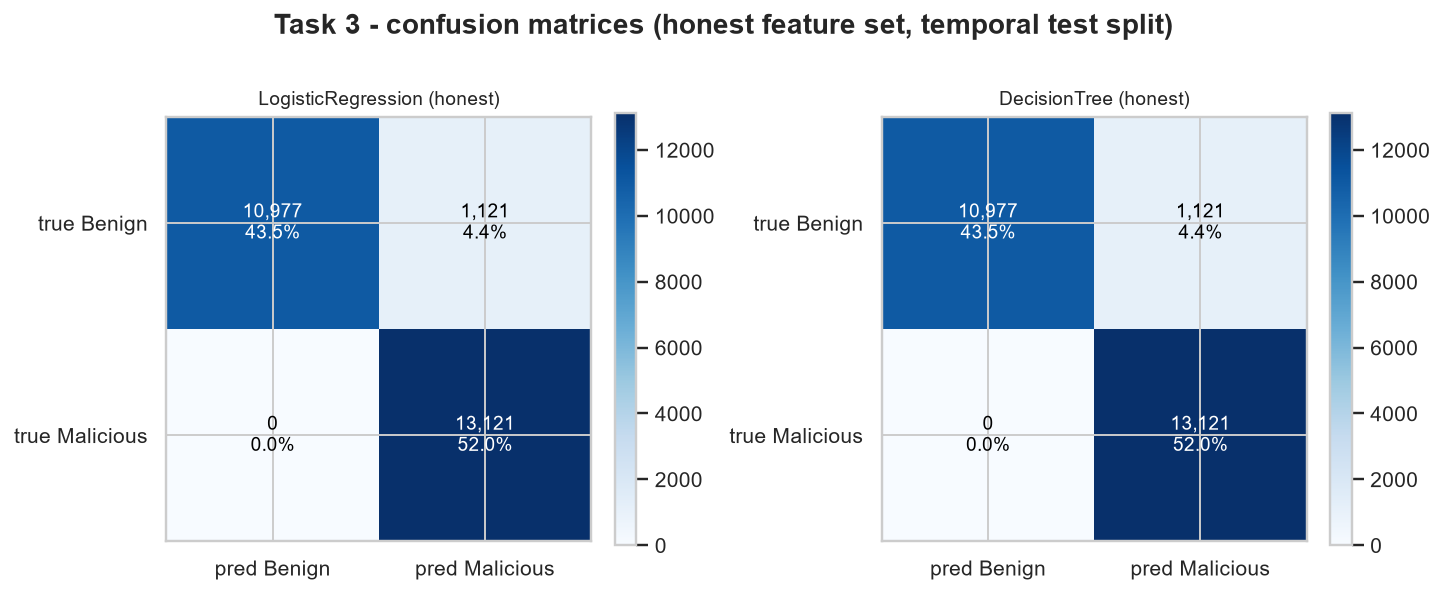

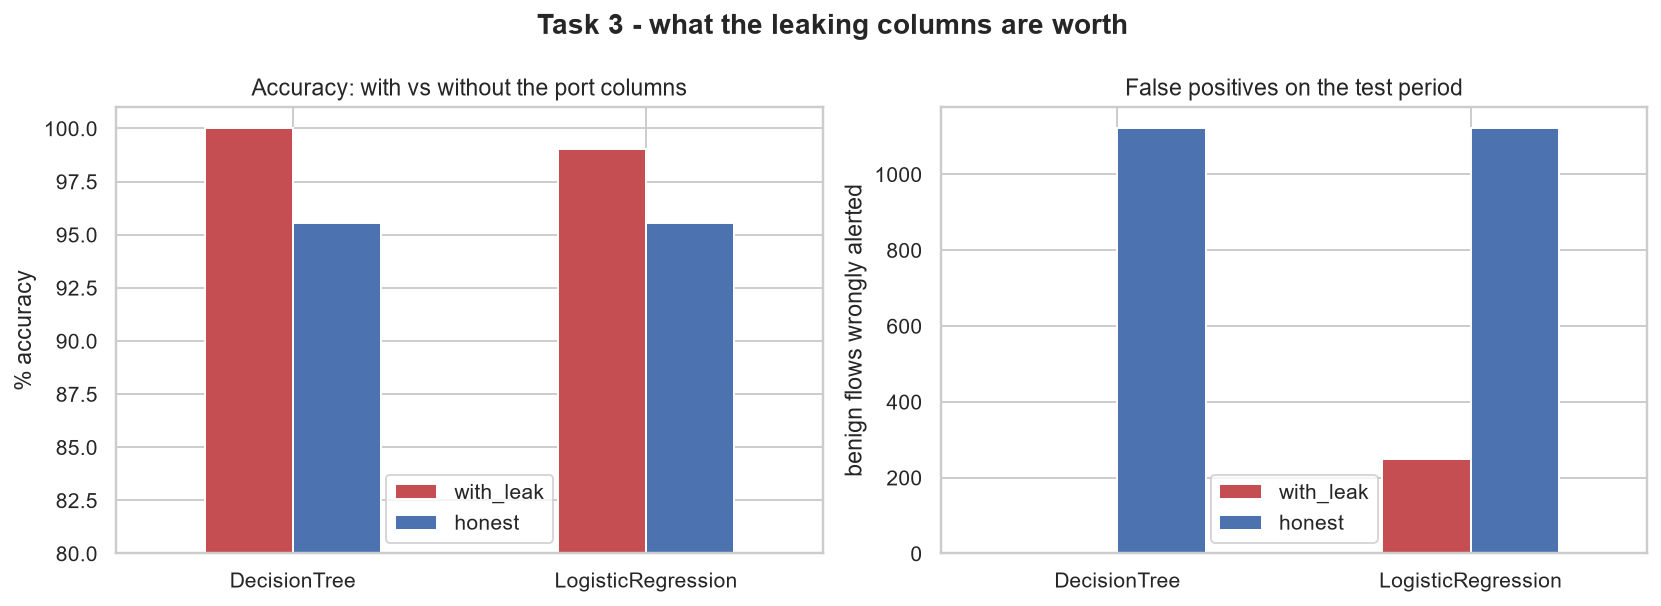

In [5]:
for name in ["fig4_ml_confusion_matrices.png", "fig5_leak_vs_honest.png"]:
    display(Image(filename=f"../outputs/figures/{name}"))

## Task 4 — Deep-learning prototype and ML vs DL comparison

Two `MLPClassifier` architectures on the identical split, preprocessing and metrics,
compared against Task 3 on training time, detection accuracy and practical feasibility.

In [6]:
import task4_dl
task4_dl.main()


1. LOAD AND SPLIT  (identical to Task 3)


  train 58,844   test 25,219
  Same split, same preprocessing, same metrics as Task 3 - otherwise
  the ML and DL numbers would not be comparable.

  Using the HONEST feature set (12 columns).
  Task 3 showed the port columns turn the problem into a lookup; a
  neural network trained on them would only memorise the same table.

2. TRAINING THE NEURAL NETWORKS



  --- MLP-small (honest) ---
  class         precision    recall        F1   support
  benign           1.0000    0.9073    0.9514    12,098
  malicious        0.9213    1.0000    0.9590    13,121
  PR-AUC (malicious) : 0.9192
  confusion          : TP 13,121  FP 1,121  FN 0  TN 10,977
  FALSE POSITIVES    : 1,121 (rate 9.27%)
  training time      : 2.304 s
  accuracy           : 95.55%   <- reported last, on purpose
  epochs run         : 11 (early stopping, cap 100)
  trainable params   : 1,089



  --- MLP-deep (honest) ---
  class         precision    recall        F1   support
  benign           1.0000    0.9073    0.9514    12,098
  malicious        0.9213    1.0000    0.9590    13,121
  PR-AUC (malicious) : 0.9243
  confusion          : TP 13,121  FP 1,121  FN 0  TN 10,977
  FALSE POSITIVES    : 1,121 (rate 9.27%)
  training time      : 11.726 s
  accuracy           : 95.55%   <- reported last, on purpose
  epochs run         : 17 (early stopping, cap 100)
  trainable params   : 14,593

3. ML vs DL COMPARISON
          family          algorithm  accuracy  precision_malicious  recall_malicious  f1_malicious  pr_auc_malicious  false_positives  train_seconds
Machine Learning LogisticRegression    0.9555               0.9213            1.0000        0.9590            0.9244             1121         0.5360
Machine Learning       DecisionTree    0.9555               0.9213            1.0000        0.9590            0.9211             1121         0.4800
   Deep Learning         

  wrote outputs\figures\fig6_ml_vs_dl.png
  wrote outputs\tables\task4_ml_vs_dl.csv
  wrote outputs\tables\task4_dl_collapse_check.csv

Task 4 complete.


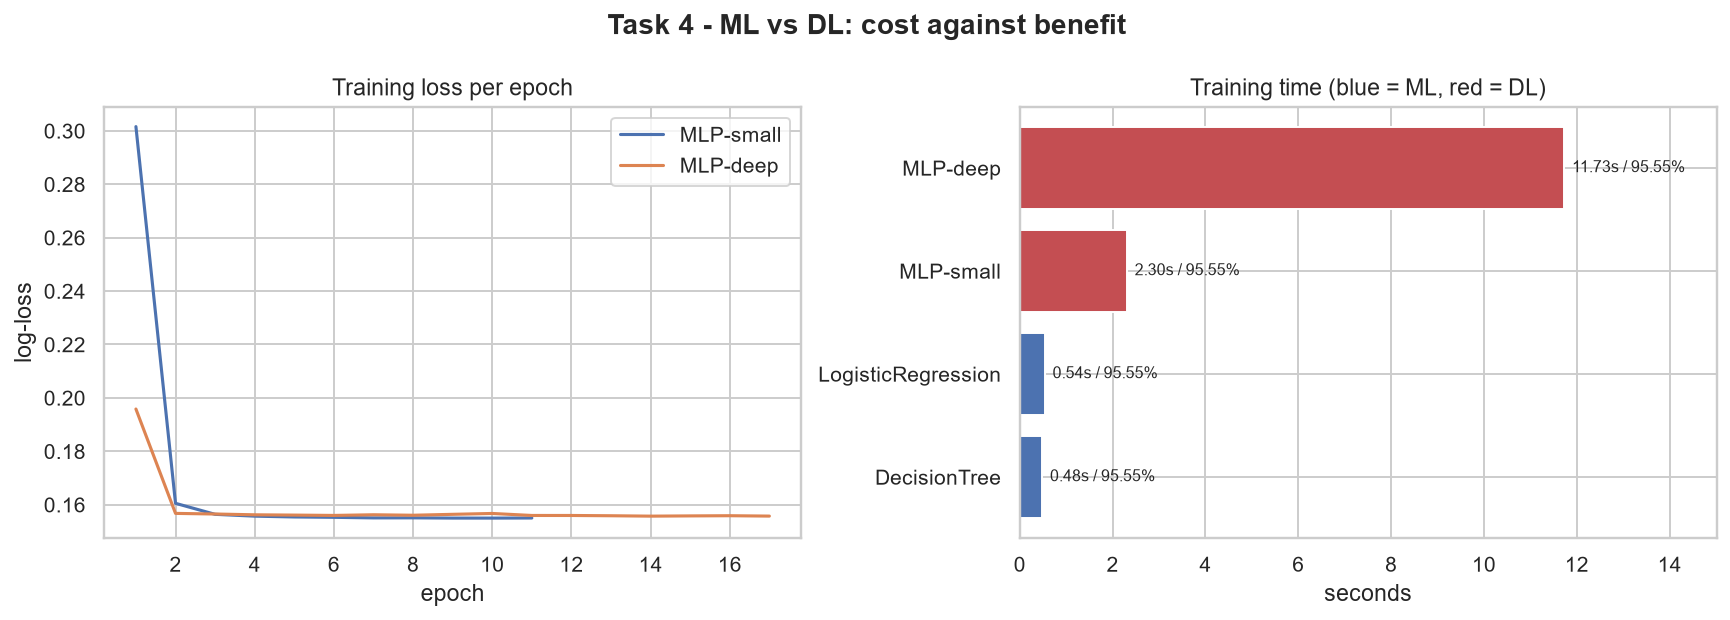

In [7]:
display(Image(filename="../outputs/figures/fig6_ml_vs_dl.png"))

## Summary

All four models — Logistic Regression, Decision Tree, MLP-small and MLP-deep — reach
**identical** performance (95.55% accuracy, 1,121 false positives) and every one of them
agrees with the rule `proto == tcp` on 100% of test predictions.

The deep network costs ~23× the training time for +0.00 percentage points.

The ceiling is the dataset, not the model: benign traffic here is UDP that got answered
and malicious traffic is TCP SYNs that did not. The honest next step is windowed
behavioural features (per-host fan-out, connection rate, share unanswered), not a
larger network.